# Circle (CRCL) valuation with stochastic interest rates and USDC supply

Question: how much is Circle worth when revenue depends on stochastic rates and USDC supply, and which rate path does today's share price imply?

## 0. Setup

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
import requests
from scipy import stats, optimize
import statsmodels.api as sm

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams["figure.figsize"] = (10, 4)
rng = np.random.default_rng(42)  # fixed seed so Monte Carlo is reproducible

START_RATES = "2000-01-01"
START_CRCL = "2025-06-01"
END_DATE = "2026-10-17"  # data cutoff: all series are cut here so results do not change with each run
CIK_CIRCLE = "0001876042"

## 1. Data collection
### 1.1 CRCL price (yfinance)

[*********************100%***********************]  1 of 1 completed


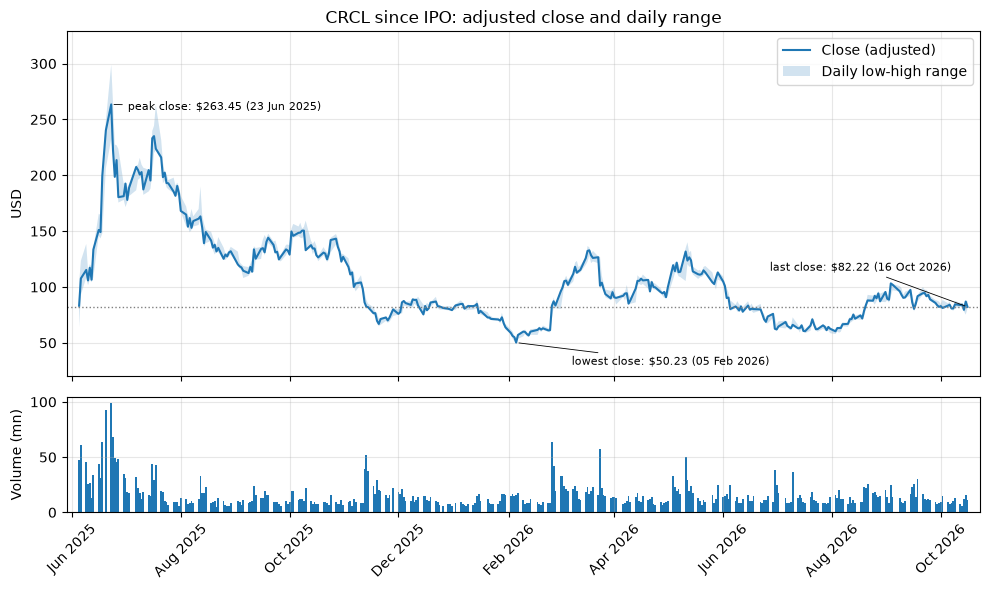

In [143]:
crcl = yf.download("CRCL", start=START_CRCL, auto_adjust=True)
crcl.columns = crcl.columns.droplevel("Ticker")
crcl.columns.name = None
crcl = crcl.loc[:END_DATE]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(crcl.index, crcl["Close"], lw=1.5, label="Close (adjusted)")
ax1.fill_between(crcl.index, crcl["Low"], crcl["High"], alpha=0.2, label="Daily low-high range")
marks = {  # label: (date, text offset in points, horizontal alignment)
    "peak close": (crcl["Close"].idxmax(), (12, -4), "left"),
    "lowest close": (crcl["Close"].idxmin(), (40, -16), "left"),
    "last close": (crcl.index[-1], (-12, 26), "right"),
}
for name, (d, offset, ha) in marks.items():
    ax1.annotate(f"{name}: ${crcl.loc[d, 'Close']:.2f} ({d:%d %b %Y})", xy=(d, crcl.loc[d, "Close"]),
                 xytext=offset, textcoords="offset points", ha=ha, fontsize=8,
                 arrowprops=dict(arrowstyle="-", lw=0.6))
ax1.axhline(crcl["Close"].iloc[-1], ls=":", lw=1, color="gray")  # today's price as reference
ax1.margins(y=0.12)
ax1.set_ylabel("USD")
ax1.set_title("CRCL since IPO: adjusted close and daily range")
ax1.legend(loc="upper right")
ax2.bar(crcl.index, crcl["Volume"] / 1e6, width=1.0)
ax2.set_ylabel("Volume (mn)")
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[2, 4, 6, 8, 10, 12]))  # fixed even months, independent of the data limits
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.tick_params(axis="x", labelrotation=45)
ax2.set_xlim(crcl.index[0] - pd.Timedelta(days=7), crcl.index[-1] + pd.Timedelta(days=7))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation (CRCL).** CRCL went public on 5 Jun 2025 (open $69.00, close $83.23), reached its highest close of $263.45 on 23 Jun 2025 (intraday high $298.99) and its lowest close of $50.23 on 5 Feb 2026. The last close is $82.22 on 16 Oct 2026: 69% below the peak and about the same as the IPO-day close (-1.2%). Volume peaked during the run-up (99 mn shares on 23 Jun 2025) and is now about 11 mn shares a day (20-day mean), against a median of 12 mn. The price the model will be compared with is therefore the one after a large fall from the peak, not the IPO price.

### 1.2 3-month T-bill (FRED DTB3)
Daily series DTB3 from FRED, starting in 2000 so the sample includes several rate regimes. It is the proxy for the reserve return that the rate model will simulate.

,tbill_3m
observation_date,
2026-10-09,4.06
2026-10-13,4.09
2026-10-14,4.10
2026-10-15,4.10
2026-10-16,4.08


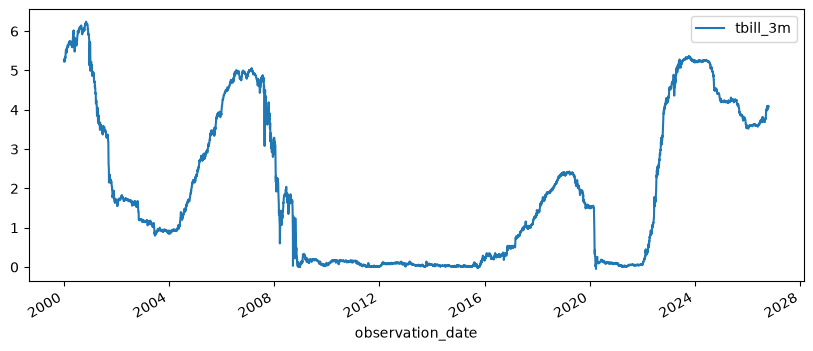

In [144]:
tbill = pd.read_csv(
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3",
    index_col=0, parse_dates=True, na_values=".",
).rename(columns={"DTB3": "tbill_3m"})
tbill = tbill.loc[START_RATES:END_DATE].dropna()
tbill.plot();
tbill.tail()

**Interpretation (T-bill):** The 3-month T-bill rate is 4.08% on 16 Oct 2026. Since 2000 it has moved between very different regimes: annual averages of 5.82% in 2000, 1.01% in 2003, 4.73% in 2006 and 5.07% in 2023. It stayed below 0.25% from March 2009 to December 2015 and from April 2020 to February 2022, about a third of the sample, with a low of -0.05% in March 2020. Reserve income depends on short-term rates: the quarterly average of the T-bill (4.23, 4.10, 3.73, 3.59 and 3.62%) stays within 0.13 pp of the reserve return rate that Circle reports (4.1, 4.2, 3.8, 3.5 and 3.5%), so the T-bill is a reasonable driver for the rate model. Limitation: a Vasicek model allows negative rates and has a single long-run mean, while this sample mixes near-zero and 5% regimes, so the calibrated mean will depend on the window chosen.

### 1.3 USDC supply (DefiLlama, id 2)
Daily circulating USDC supply in USD, full history since 2018. Steps: download, build the DataFrame, check quarter-end values.

In [145]:
url = "https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=2"
raw = requests.get(url, timeout=30)
raw.raise_for_status()
usdc_raw = raw.json()
print(len(usdc_raw))
usdc_raw[0], usdc_raw[-1]

2964


({'date': '1536624000',
  'totalCirculating': {'peggedUSD': 2},
  'totalCirculatingUSD': {'peggedUSD': 2}},
 {'date': '1792627200',
  'totalCirculating': {'peggedUSD': 72659635020.05},
  'totalUnreleased': {'peggedUSD': 1358648150.4},
  'totalCirculatingUSD': {'peggedUSD': 72619705409.22},
  'totalMintedUSD': {'peggedUSD': 0},
  'totalBridgedToUSD': {'peggedUSD': 0}})

,usdc_supply
date,
2026-10-13,"72,860,344,009.00"
2026-10-14,"73,133,116,485.00"
2026-10-15,"72,763,096,585.00"
2026-10-16,"72,828,793,768.00"
2026-10-17,"72,734,876,026.00"


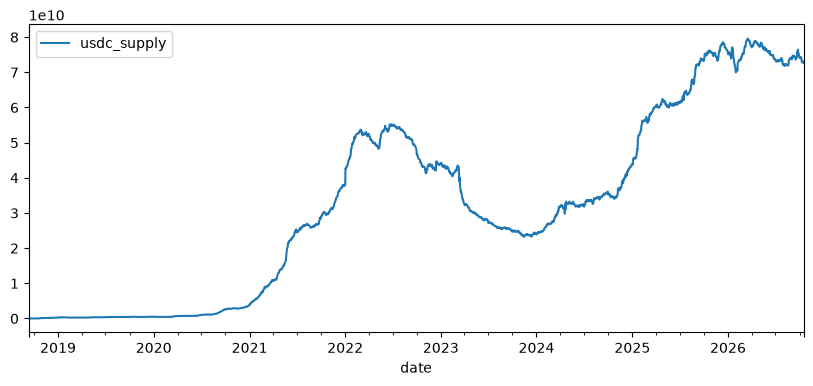

In [146]:
usdc = pd.DataFrame(
    {
        "date": pd.to_datetime([int(x["date"]) for x in usdc_raw], unit="s"),
        "usdc_supply": [x["totalCirculatingUSD"]["peggedUSD"] for x in usdc_raw],
    }
).set_index("date")
usdc = usdc.loc[:END_DATE]
usdc.plot();
usdc.tail()

In [147]:
# Quarter-end USDC supply, $ bn. The last row is partial: data is cut at END_DATE (2026-10-17), it is not a quarter end.
(usdc["usdc_supply"].resample("QE").last() / 1e9).round(1).loc["2021":]

date
2021-03-31   10.90
2021-06-30   24.60
2021-09-30   28.70
2021-12-31   38.10
2022-03-31   52.50
2022-06-30   54.90
2022-09-30   47.90
2022-12-31   44.10
2023-03-31   32.60
2023-06-30   27.70
2023-09-30   24.70
2023-12-31   24.00
2024-03-31   31.90
2024-06-30   31.90
2024-09-30   36.00
2024-12-31   43.80
2025-03-31   60.30
2025-06-30   61.30
2025-09-30   73.20
2025-12-31   76.00
2026-03-31   77.40
2026-06-30   73.70
2026-09-30   74.60
2026-12-31   72.70
Freq: QE-DEC, Name: usdc_supply, dtype: float64

**Interpretation (USDC):** USDC supply peaked at $55.2bn on 20 Jun 2022, fell to $23.2bn on 15 Nov 2023 (-58%), reached a high of $79.6bn on 18 Mar 2026 and stands at $72.7bn on 17 Oct 2026. The fall began in mid-2022 and was sharpest around March 2023: supply went from $43.2bn on 8 Mar to $38.0bn on 15 Mar, the week of the SVB failure. Since the start of 2026 it has moved between $70.0bn and $79.6bn. The series has three regimes (growth, decline, recovery) followed by a plateau, so a single growth rate depends on the calibration window.

**SVB / regime decision:** which window calibrates USDC growth is decided in section 3, and the result under other windows is shown as a sensitivity.

### 1.4 Circle quarterly figures (releases, 10-Q/10-K, S-1)
Every hand-entered number cites its source in a comment.

In [148]:
# Circle quarterly figures, $ billions (USDC) and $ millions (income). Q2 2025 to Q2 2026.
# Sources (8-K exhibit 99.1, earnings releases):
#  Q2 2025: sec.gov/Archives/edgar/data/1876042/000162828025039749/q22025epr.htm
#  Q3 2025: sec.gov 8-K 0001876042-25-000045 (release of 2025-11-12; table read from the Business Wire copy)
#  Q4 2025: sec.gov/Archives/edgar/data/1876042/000187604226000032/final_circlereportsfourt.htm
#  Q1 2026: sec.gov/Archives/edgar/data/0001876042/000187604226000148/final_05x11q1epr30.htm
#  Q2 2026: sec.gov/Archives/edgar/data/1876042/000187604226000246/augustepr-circle_q22026f.htm
circle_q = pd.DataFrame(
    {
        "avg_usdc_bn":       [61.0, 67.8, 76.2, 75.2, 76.5],   # Key Operating Indicators
        "end_usdc_bn":       [61.3, 73.7, 75.3, 77.0, 73.3],   # Key Operating Indicators
        "reserve_return_pct":[4.1,  4.2,  3.8,  3.5,  3.5],    # Key Operating Indicators
        "reserve_income":    [634,  711,  733,  653,  668],    # Quarterly Results of Operations
        "total_revenue":     [658,  740,  770,  694,  701],    # idem
        "dist_trans_costs":  [406,  447,  461,  405,  410],    # distribution and transaction costs
        "total_costs":       [407,  448,  461,  407,  412],    # distribution, transaction and other costs
        "rldc":              [251,  292,  309,  287,  289],    # revenue less distribution costs
    },
    index=pd.PeriodIndex(["2025Q2", "2025Q3", "2025Q4", "2026Q1", "2026Q2"], freq="Q"),
)
circle_q

,avg_usdc_bn,end_usdc_bn,reserve_return_pct,reserve_income,total_revenue,dist_trans_costs,total_costs,rldc
2025Q2,61.00,61.30,4.10,634,658,406,407,251
2025Q3,67.80,73.70,4.20,711,740,447,448,292
2025Q4,76.20,75.30,3.80,733,770,461,461,309
2026Q1,75.20,77.00,3.50,653,694,405,407,287
2026Q2,76.50,73.30,3.50,668,701,410,412,289


In [149]:
# Consistency checks on the hand-entered table
assert ((circle_q["total_revenue"] - circle_q["total_costs"] - circle_q["rldc"]).abs() <= 1).all()  # RLDC = revenue - costs (rounding tolerance 1)
implied = circle_q["avg_usdc_bn"] * 1e3 * circle_q["reserve_return_pct"] / 100 / 4  # avg USDC x reserve return / 4, $ mn
(implied - circle_q["reserve_income"]).round(0)

2025Q2   -9.00
2025Q3    1.00
2025Q4   -9.00
2026Q1    5.00
2026Q2    1.00
Freq: Q-DEC, dtype: float64

**Interpretation (Circle table):** The table has five quarters (Q2 2025 to Q2 2026) taken from Circle's earnings releases (8-K). Reserve income is explained by average USDC times the reserve return rate: the implied figure is within $9mn of the reported one in every quarter (under 1.5%), consistent with the return rate being rounded to one decimal. Distribution and transaction costs are 61% to 64% of reserve income (61.4% in Q2 2026), and the RLDC margin is 38% to 41% of total revenue. Average USDC grew from $61.0bn to $76.5bn while the reserve return rate fell from 4.1% to 3.5%, and reserve income stayed between $634mn and $733mn. These two moves happened in the same period, but five points cannot show a relationship between them. Limitation: five quarters allow calibrating margins and the cost share, not estimating a statistical pattern, and the sample covers only a period of falling rates.

### 1.5 Save raw data

In [150]:
crcl.to_csv("../data/crcl_prices.csv")
tbill.to_csv("../data/tbill_3m.csv")
usdc.to_csv("../data/usdc_supply.csv")
circle_q.to_csv("../data/circle_quarterly.csv")

## 2. Unit economics
Goal: reduce Circle's quarterly results to per-dollar-of-USDC quantities, which are what the model will project later.

Definitions used below (all from the table in 1.4, quarterly figures in $ mn unless noted):
- **Reserve income**: interest earned on the reserves backing USDC.
- **Distribution and transaction costs**: mostly payments to partners such as Coinbase.
- **RLDC** (revenue less distribution and transaction costs): the profit measure Circle reports before operating expenses.
- **RLDC yield**: annualised RLDC divided by average USDC. It is the profit Circle earns per year for each dollar of USDC in circulation.

### 2.1 Reserve income identity
Check that reserve income is explained by average USDC times the reserve return.

In [151]:
uq = circle_q.copy()
uq["implied_return_pct"] = uq["reserve_income"] * 4 / (uq["avg_usdc_bn"] * 1e3) * 100  # annualised reserve income / avg USDC
uq[["implied_return_pct", "reserve_return_pct"]]

,implied_return_pct,reserve_return_pct
2025Q2,4.16,4.10
2025Q3,4.19,4.20
2025Q4,3.85,3.80
2026Q1,3.47,3.50
2026Q2,3.49,3.50


**Interpretation (reserve income).** The implied return is within 0.06 pp of the reported one in all five quarters, and the gap is consistent with Circle reporting the return rounded to one decimal. Reserve income is therefore average USDC times the reserve return, so the model needs only these two variables.

### 2.2 Cost structure
How much of reserve income is passed on to partners, how much revenue is not reserve income, and the resulting RLDC margin.

In [152]:
uq["dist_share"] = uq["dist_trans_costs"] / uq["reserve_income"]  # distribution and transaction costs / reserve income
uq["other_revenue"] = uq["total_revenue"] - uq["reserve_income"]  # revenue that is not reserve income, $ mn
uq["rldc_margin"] = uq["rldc"] / uq["total_revenue"]
uq[["dist_share", "other_revenue", "rldc_margin"]]

,dist_share,other_revenue,rldc_margin
2025Q2,0.64,24,0.38
2025Q3,0.63,29,0.39
2025Q4,0.63,37,0.40
2026Q1,0.62,41,0.41
2026Q2,0.61,33,0.41


**Interpretation (cost structure).** Distribution and transaction costs are 61% to 64% of reserve income (61% in 2026Q2, falling slowly), so Circle keeps about 39 cents of each dollar of reserve income. Non-reserve revenue is $24 mn to $41 mn per quarter, 3.6% to 5.9% of total revenue, and total costs exceed distribution costs by only $0 to $2 mn, so that revenue reaches RLDC almost in full. The RLDC margin on total revenue is stable at 38% to 41%. If the partner share stays constant, a $100 mn fall in reserve income lowers RLDC by about $38 mn; this assumption is tested in the sensitivity section.

### 2.3 RLDC yield
Profit per dollar of USDC, compared with the reserve return.

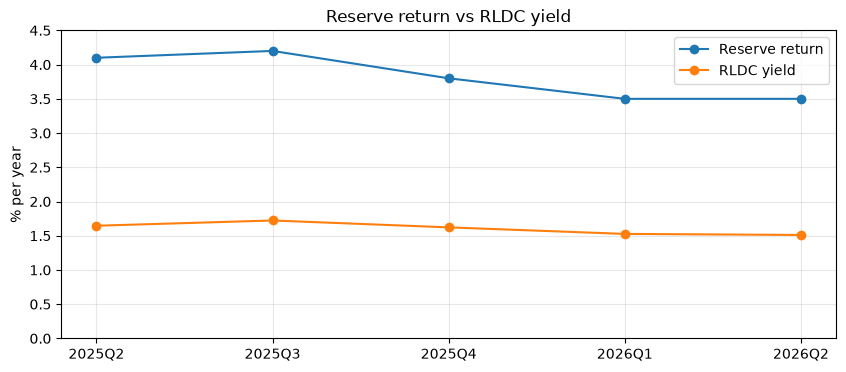

,reserve_return_pct,rldc_yield_pct
2025Q2,4.10,1.65
2025Q3,4.20,1.72
2025Q4,3.80,1.62
2026Q1,3.50,1.53
2026Q2,3.50,1.51


In [153]:
uq["rldc_yield_pct"] = uq["rldc"] * 4 / (uq["avg_usdc_bn"] * 1e3) * 100  # annualised RLDC per $ of average USDC

fig, ax = plt.subplots()
x = uq.index.astype(str)
ax.plot(x, uq["reserve_return_pct"], marker="o", label="Reserve return")
ax.plot(x, uq["rldc_yield_pct"], marker="o", label="RLDC yield")
ax.set_ylim(0, 4.5)
ax.set_ylabel("% per year")
ax.set_title("Reserve return vs RLDC yield")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

uq[["reserve_return_pct", "rldc_yield_pct"]]

**Interpretation (RLDC yield).**
- RLDC yield fell from 1.65% (2025Q2) to 1.51% (2026Q2), about 8.5%, while the reserve return fell from 4.10% to 3.50%, about 15%. The yield fell less than rates because the distribution share of reserve income dropped from 64% to 61% and non-reserve revenue grew from $24 mn to $33 mn per quarter.
- From the 2025Q3 peak (1.72% at a 4.20% return) to 2026Q2, each 1 pp drop in the reserve return cost about 0.3 pp of yield. With five quarters and non-reserve revenue growing at the same time, this is an observation, not a calibrated parameter. It is tested in the sensitivity section.

### 2.4 Operating expenses
RLDC is before operating expenses. This block adds them to get operating income and the yield that is left per dollar of USDC.

In [154]:
# Operating expenses, $ mn. Source: Circle Q2 2026 earnings release, 8-K exhibit 99.1 (five-quarter table):
# https://www.sec.gov/Archives/edgar/data/1876042/000187604226000246/augustepr-circle_q22026f.htm
# 2025Q2 includes about $435 mn of one-off stock compensation from the IPO.
uq["opex"] = [576.7, 211.1, 253.6, 242.4, 254.5]
uq["operating_income"] = uq["rldc"] - uq["opex"]
uq["opex_yield_pct"] = uq["opex"] * 4 / (uq["avg_usdc_bn"] * 1e3) * 100  # annualised opex per $ of average USDC
uq["operating_yield_pct"] = uq["rldc_yield_pct"] - uq["opex_yield_pct"]
uq[["rldc", "opex", "operating_income", "rldc_yield_pct", "opex_yield_pct", "operating_yield_pct"]]

,rldc,opex,operating_income,rldc_yield_pct,opex_yield_pct,operating_yield_pct
2025Q2,251,576.70,-325.70,1.65,3.78,-2.14
2025Q3,292,211.10,80.90,1.72,1.25,0.48
2025Q4,309,253.60,55.40,1.62,1.33,0.29
2026Q1,287,242.40,44.60,1.53,1.29,0.24
2026Q2,289,254.50,34.50,1.51,1.33,0.18


**Interpretation (operating expenses).**
- 2025Q2 is not comparable: its opex includes about $435 mn of one-off stock compensation from the IPO, which produces an operating yield of -2.14%. It is excluded from any average or calibration.

- From 2025Q3 to 2026Q2, operating income fell from $81 mn to $35 mn per quarter. RLDC stayed between $287 mn and $309 mn while opex rose from $211 mn to $255 mn (about 20%).

- Per dollar of USDC, the operating yield fell from 0.48% to 0.18%. RLDC yield fell from 1.72% to 1.51% and opex yield rose from 1.25% to 1.33%.

- The profit left after operating costs is a small difference between two large numbers (1.51% minus 1.33%), so the valuation is very sensitive to the opex assumption. Opex growth relative to USDC growth becomes a key assumption of the DCF and is tested in the sensitivity section.

- Opex includes $52 mn to $59 mn per quarter of stock-based compensation, a non-cash cost that dilutes shareholders. The DCF keeps it as a cost.

## 3. Calibration (Vasicek via AR(1), GBM for USDC)

### 3.1 Vasicek calibration (AR(1) on the 3-month T-bill)
Regress each month-end rate on the previous month-end rate and convert the coefficients into the Vasicek parameters. Month-end (point-in-time) values are used because monthly averages smooth the series and understate volatility. First pass on the full sample; other choices come next.

In [155]:
# Month-end T-bill rate, in % (point-in-time values; the last month, Oct 2026, is partial and is dropped)
rate_m = tbill["tbill_3m"].resample("ME").last().iloc[:-1]
dt = 1 / 12  # time between observations, in years

def fit_vasicek(r, dt):
    """AR(1): r[t+1] = a + b * r[t] + error. Returns the Vasicek parameters."""
    x, y = r.values[:-1], r.values[1:]
    b, a = np.polyfit(x, y, 1)                # slope and intercept of the regression
    s = (y - (a + b * x)).std(ddof=2)         # std of the regression residual
    kappa = -np.log(b) / dt                   # speed of mean reversion, per year
    theta = a / (1 - b)                       # long-run mean, in %
    sigma = s * np.sqrt(2 * kappa / (1 - b**2))  # volatility, in % per sqrt(year)
    return {"a": a, "b": b, "kappa": kappa, "theta": theta, "sigma": sigma, "half_life_years": np.log(2) / kappa}

pd.Series(fit_vasicek(rate_m, dt))

a                 0.01
b                 0.99
kappa             0.11
theta             1.44
sigma             0.72
half_life_years   6.07
dtype: float64

**Interpretation (historical fit).** The full-sample AR(1) on month-end rates gives b = 0.991, kappa = 0.11, theta = 1.44% and sigma = 0.72, with a half-life of 6.1 years. Theta is below every rate regime in the sample: it averages the near-zero periods (about a third of the sample) with the 4-5% periods. Used as a base case, it would assume a large fall in rates by construction of the window. It is kept as the stress case. With monthly averages instead of month-end values, sigma would be 0.65: averaging smooths the series.

### 3.2 Vasicek parameters: base case and stress case
Base case: theta = Fed median longer-run rate (3.2%, September 2026 projections); kappa fitted so the model reproduces the Fed's median path for 2026-2029; sigma from the historical fit in 3.1. Stress case: the full-sample historical fit from 3.1.

In [156]:
hist = fit_vasicek(rate_m, dt)  # historical fit from 3.1 (full sample)
r0 = tbill["tbill_3m"].iloc[-1]  # last T-bill observation, %
THETA_BASE = 3.2  # Fed longer-run median, September 2026 projections
# Fed median fed funds rate by year end, September 2026 projections:
# https://federalreserve.gov/monetarypolicy/fomcprojtabl20260916.htm
fed = pd.Series({2026: 4.1, 2027: 4.1, 2028: 3.9, 2029: 3.6})
t_fed = (fed.index + 1 - 2026.8).values  # years from late Oct 2026 to each year end

def path(kappa, theta, t):
    """Expected Vasicek rate at time t: theta + (r0 - theta) * exp(-kappa * t)."""
    return theta + (r0 - theta) * np.exp(-kappa * t)

loss = lambda k: ((path(k, THETA_BASE, t_fed) - fed.values) ** 2).sum()
kappa_base = optimize.minimize_scalar(loss, bounds=(0.01, 3), method="bounded").x

params = {
    "base":   {"kappa": kappa_base,    "theta": THETA_BASE,    "sigma": hist["sigma"]},
    "stress": {"kappa": hist["kappa"], "theta": hist["theta"], "sigma": hist["sigma"]},
}
pd.DataFrame(params).T

,kappa,theta,sigma
base,0.15,3.20,0.72
stress,0.11,1.44,0.72


**Interpretation (base and stress parameters).** Base case: theta = 3.2% (Fed median longer-run rate, September 2026 projections; participants range from 2.9% to 3.9%), kappa = 0.15 fitted to the Fed median path, sigma = 0.72 from history. The fitted path (4.05, 3.93, 3.83, 3.74%) is within 0.17 pp of the Fed medians (4.1, 4.1, 3.9, 3.6%). Expected rate in 1, 5 and 10 years: 3.96%, 3.61%, 3.39% (base) and 3.79%, 2.93%, 2.28% (stress). Limitation: the Fed projects the federal funds rate, not the T-bill (4.1% vs 4.08% today), and its projections are committee medians, not market forecasts.

### 3.3 GBM for USDC: growth and volatility by window
Month-end USDC supply and monthly log returns. For a GBM, the mean of the log return is mu - sigma^2/2 (Ito correction), so mu = mean log return + sigma^2/2. Monthly data are used because daily data hide the persistence of USDC flows and contain isolated jumps that look like counting errors (for example -6.8%, +8.4% and +7.0% between 18 and 22 April 2024).

In [157]:
usdc_bn = usdc["usdc_supply"] / 1e9
usdc_m = usdc_bn.resample("ME").last().iloc[:-1]  # month-end supply, $ bn (partial Oct 2026 dropped)
logret = np.log(usdc_m).diff().dropna()            # monthly log returns

def fit_gbm(lr, per_year=12):
    """GBM from monthly log returns: sigma = std * sqrt(12); mu = mean * 12 + sigma^2 / 2 (Ito)."""
    sigma = lr.std() * np.sqrt(per_year)
    mean_log = lr.mean() * per_year
    return {"months": len(lr), "mean_log_growth_pct": mean_log * 100, "mu_pct": (mean_log + sigma**2 / 2) * 100, "sigma_pct": sigma * 100}

windows = {  # months of the returns; each return runs from the previous month end
    "since 2021-01": ("2021-01", None),
    "peak to trough (Jun 2022 to Nov 2023)": ("2022-07", "2023-11"),
    "since trough (Nov 2023)": ("2023-12", None),
    "since 2024-01": ("2024-01", None),
    "since 2025-01": ("2025-01", None),
    "last 12 months": ("2025-10", None),
}
print(f"Autocorrelation of monthly returns since 2021: {logret.loc['2021-01':].autocorr():.2f}")
pd.DataFrame({k: fit_gbm(logret.loc[a:b]) for k, (a, b) in windows.items()}).T

Autocorrelation of monthly returns since 2021: 0.64


,months,mean_log_growth_pct,mu_pct,sigma_pct
since 2021-01,69.00,52.19,60.66,41.15
peak to trough (Jun 2022 to Nov 2023),17.00,-59.00,-56.68,21.51
since trough (Nov 2023),34.00,40.33,42.27,19.71
since 2024-01,33.00,41.20,43.19,19.96
since 2025-01,21.00,30.40,32.36,19.78
last 12 months,12.00,1.86,2.76,13.38


**Interpretation (USDC by window).** Expected growth (mu) ranges from -57% to +61% a year depending on the window, and volatility from 13% to 41%. Expected growth (mu) was 42% a year from the November 2023 trough (about 50% a year compounded), but USDC was flat over the last 12 months (mu +2.8%). Monthly returns are persistent (autocorrelation 0.64 since 2021): once USDC starts growing or shrinking, it tends to continue for months. A GBM assumes independent shocks and does not capture this; the growth scenarios in 3.4 cover changes of regime, and sigma covers fluctuations within each scenario. With daily data, sigma since 2021 would be 17% instead of 41%, because daily returns hide this persistence. No window can be used alone as a 10-year forecast.

### 3.4 USDC volatility, correlation and growth scenarios
Sigma of USDC from month-end returns since 2022 (excludes 2021, when USDC grew from $3.7bn to $38bn; includes the 2022-23 decline and the recovery). Correlation between monthly rate changes and monthly USDC log returns since 2022 (same window as sigma). Growth scenarios are anchored on external sources or observed data until 2030 and then fade to long-run nominal growth. All parameters are stored in decimals in `calib`.

In [158]:
pd.set_option("display.max_colwidth", None)  # show full text in table cells

shocks = pd.DataFrame({"d_rate": rate_m.diff(), "usdc_logret": logret}).loc["2022-01":].dropna()  # same window as sigma
rho, p_value = stats.pearsonr(shocks["d_rate"], shocks["usdc_logret"])
sigma_usdc = fit_gbm(logret.loc["2022-01":])["sigma_pct"] / 100  # month-end returns since 2022
print(f"rho = {rho:.2f}, p-value = {p_value:.3f}, months = {len(shocks)}")
print(f"sigma USDC = {sigma_usdc:.3f} (monthly returns since 2022-01)")

# USDC growth scenarios. The drift changes with time:
# stage 1 (now to end 2030): scenario growth; stage 2 (2031 to year 10): linear fade to long-run growth.
S0 = usdc_bn.iloc[-1]  # USDC supply at END_DATE, $ bn
T1 = 2031 - 2026.8     # years from late Oct 2026 to end 2030
HORIZON = 10           # projection horizon, years
G_LONG = 0.04          # long-run nominal growth: Fed longer-run real GDP 2.0% + PCE inflation 2.0% (Sep 2026 projections)
STABLE_NOW, STABLE_2030 = 309, 2000  # stablecoin supply now and 2030 forecast, $ bn (Standard Chartered, 14 Oct 2026)
mu1 = {
    "bear": 0.0,                                    # flat: last-12-month growth is -3.6% to +2.8% depending on the end dates
    "base": np.log(1.4),                            # Circle 40% through-cycle CAGR target
    "bull": np.log(STABLE_2030 / STABLE_NOW) / T1,  # market reaches $2tn, USDC keeps its share
}

def mu_t(t, m1):
    """Drift at time t (years): m1 until T1, then linear fade to log(1 + G_LONG) at HORIZON."""
    m_long = np.log(1 + G_LONG)
    w = np.clip((t - T1) / (HORIZON - T1), 0, 1)
    return m1 + (m_long - m1) * w

def expected_usdc(t, m1, n=2001):
    """E[S_t] = S0 * exp(integral of mu from 0 to t), integral by the trapezoid rule."""
    s = np.linspace(0, t, n)
    m = mu_t(s, m1)
    return S0 * np.exp(((m[1:] + m[:-1]) / 2 * np.diff(s)).sum())

# Everything the simulation needs, in decimals (rates converted from %)
calib = {
    "r0": r0 / 100,
    "rates": {k: {"kappa": v["kappa"], "theta": v["theta"] / 100, "sigma": v["sigma"] / 100} for k, v in params.items()},
    "S0": S0, "T1": T1, "HORIZON": HORIZON, "G_LONG": G_LONG,
    "mu1": mu1, "sigma_usdc": sigma_usdc, "rho": rho,
}

sources = {
    "bear": "Flat: observed growth over the last 12 months",
    "base": "Circle 40% CAGR target",
    "bull": "Standard Chartered $2tn market, constant USDC share",
}
scenarios = pd.DataFrame({
    "Source": sources,
    "mu to 2030 (continuous)": mu1,
    "Annual growth to 2030 (%)": {k: (np.exp(m) - 1) * 100 for k, m in mu1.items()},
    "USDC 2030 ($ bn)": {k: expected_usdc(T1, m) for k, m in mu1.items()},
    "Share of $2tn market (%)": {k: expected_usdc(T1, m) / STABLE_2030 * 100 for k, m in mu1.items()},
    "USDC year 10, mean ($ bn)": {k: expected_usdc(HORIZON, m) for k, m in mu1.items()},
    "USDC year 10, median ($ bn)": {k: expected_usdc(HORIZON, m) * np.exp(-sigma_usdc**2 * HORIZON / 2) for k, m in mu1.items()},
}).loc[["bear", "base", "bull"]]
scenarios

rho = -0.27, p-value = 0.046, months = 57
sigma USDC = 0.266 (monthly returns since 2022-01)


,Source,mu to 2030 (continuous),Annual growth to 2030 (%),USDC 2030 ($ bn),Share of $2tn market (%),"USDC year 10, mean ($ bn)","USDC year 10, median ($ bn)"
bear,Flat: observed growth over the last 12 months,0.00,0.00,72.73,3.64,81.50,57.15
base,Circle 40% CAGR target,0.34,40.00,298.87,14.94,888.48,623.09
bull,"Standard Chartered $2tn market, constant USDC share",0.44,56.00,470.78,23.54,"1,915.30","1,343.20"


**Interpretation (calibration summary).**
- Growth until end 2030: bear 0% (flat: growth over the last 12 months was -3.6% measured from 17 Oct to 17 Oct and +2.8% measured from end of September to end of September; USDC stays at $73bn); base 40% a year, Circle's through-cycle CAGR target ($299bn in 2030, 15% of Standard Chartered's $2tn stablecoin market, so USDC loses share to competitors); bull 56% a year (the market reaches $2tn and USDC keeps its 23.5% share: $471bn in 2030). The Standard Chartered forecast is read as end of 2030, and Circle's multi-year target (no end date given) is applied until end 2030.

- From 2031, growth fades linearly to 4% a year in year 10 (Fed longer-run real GDP 2.0% plus PCE inflation 2.0%, September 2026 projections). Expected (mean) USDC in year 10: $82bn (bear), $888bn (base) and $1.9tn (bull). With sigma of 27%, the median is about 30% lower ($57bn, $623bn and $1.3tn): a few very high paths pull the mean up, so the mean is not the typical outcome.

- Both external anchors lean optimistic: Standard Chartered already moved its $2tn forecast from 2028 to 2030 after supply stalled at $300-320bn, and the 40% target is set by Circle's management. The bear case uses observed data for that reason.

- Sigma of USDC = 27% a year, from month-end returns since 2022.

- Rho = -0.27 (p = 0.046, 57 months since 2022): higher rates coincide with lower USDC supply, as in 2022. Across windows (since 2021 or 2022) and methods (rate changes or AR(1) residuals), rho stays between -0.24 and -0.30, always with a p-value below 0.05. This is a partial natural hedge: when rates fall, the yield per dollar falls but USDC tends to grow.

- Circle's 2026 guidance for other revenue ($310-330 mn) includes ARC token presale revenue, which looks non-recurring. It is treated separately in the DCF.

## 4. Monte Carlo and DCF

In [159]:
# TODO

## 5. Validation against closed form

In [160]:
# TODO

## 6. Implied interest rate

In [161]:
# TODO

## 7. Sensitivity and rate-cut scenario

In [162]:
# TODO

## 8. Conclusions and limitations